# Simple flare search with NEMESIS: showcase reproduction

This notebook demonstrates a simple but compact, **FINDFLARE-style**
three-threshold / consecutive-cadence algorithm for quick outlier detection for stellar flares, inspired by [Chang et al. 2015](https://ui.adsabs.harvard.edu/abs/2015ApJ...814...35C/abstract)

The showcase uses `N1=2`, `N2=1`, `N3=3`, a global median and MAD, and
positive excursions in **PLD Flux**. It has a plotting typo (`ax` instead
of `ax1`), fixed here. Its outlier setting `Nsigma=[inf, 2]` would clip high
outliers in v1.96: we disable pipeline outlier removal for this flare
example to avoid suppressing positive flare candidates.

In [1]:
from __future__ import annotations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import median_abs_deviation


def simple_findflare(
    flux: np.ndarray,
    error: np.ndarray,
    n1: float = 2.0,
    n2: float = 1.0,
    n3: int = 3,
) -> np.ndarray:
    """Flag runs of >=n3 positive excursions (showcase's simple algorithm).

    The three tests follow the screenshot: positive residual (T0>0),
    |residual| / MAD > n1, and |residual + error| / MAD > n2.
    This is a deliberately minimal, global-baseline demonstration, not
    completeness-calibrated flare photometry.

    Based on FINDFLARE from Chang et al. 2015
    (https://ui.adsabs.harvard.edu/abs/2015ApJ...814...35C/abstract)

    >>> simple_findflare(np.array([1, 1, 1, 1, 1, 1, 1]),
    ...                  np.full(7, 0.01)).any()
    False
    """
    flux = np.asarray(flux, dtype=float)
    error = np.asarray(error, dtype=float)
    if flux.ndim != 1 or error.shape != flux.shape:
        raise ValueError('flux and error must be equally sized 1-D arrays')
    if int(n3) < 1:
        raise ValueError('n3 must be a positive integer')
    valid = np.isfinite(flux) & np.isfinite(error) & (error >= 0)
    result = np.zeros(flux.size, dtype=bool)
    if valid.sum() < 4:
        return result
    median = float(np.median(flux[valid]))
    sigma = float(median_abs_deviation(flux[valid], scale=1.0))
    if not np.isfinite(sigma) or sigma <= 0:
        return result
    residual = flux - median
    t0 = residual
    t1 = np.abs(residual) / sigma
    t2 = np.abs(residual + error) / sigma
    selected = valid & (t0 > 0) & (t1 > n1) & (t2 > n2)
    runs = np.diff(np.r_[False, selected, False].astype(int))
    starts = np.flatnonzero(runs == 1)
    stops = np.flatnonzero(runs == -1)
    for start, stop in zip(starts, stops):
        if stop - start >= int(n3):
            result[start:stop] = True
    return result

## Apply it to the three TESS sectors in the showcase

Set `RUN_DOWNLOAD=True` once to produce the real NEMESIS light curve. This
uses the same TIC and sectors as the executed showcase, but disables outlier
removal to retain positive excursions. It also disables transit searches,
which are not needed for stellar flare exploration.

In [2]:
from nemesis_tess import full_pipeline, default_NEMESIS_pipeline_settings
from nemesis_tess.pipeline import pd_to_lk

TIC_ID = 260506296  # executed TIC in the showcase (not the heading TIC)
SECTORS = [1, 2, 3]
output = Path.home() / 'nemesis_tutorials' / 'flare_tic260506296_s1_s3'
output.mkdir(parents=True, exist_ok=True)
RUN_DOWNLOAD = False  # enable to obtain TESS data before the first analysis
RUN_DOWNLOAD = True  # set True to fetch the FFI light curve

if RUN_DOWNLOAD:
    settings = default_NEMESIS_pipeline_settings()
    settings['do_transit_search'] = False
    settings['get_all_sectors'] = False
    settings['remove_outliers'] = False  # preserve positive events

    # Use TIC rather than Gaia for the diagnostic cutout overlay.
    settings['plot_catalog_source'] = 'TIC'
    hdu, lc_df, transit_results, run_settings = full_pipeline(
        ID=TIC_ID, path=str(output) + '/', cadence='30 minute',
        Sector=SECTORS, settings=settings,
    )
    assert lc_df is not None and not lc_df.empty
    assert transit_results is None

lc_path = (output / 'Multi_Sector' / 'NEMESIS_FFI_LCs' /
           f'TIC_{TIC_ID}_Multi_Sector_final_LC.csv')
if not lc_path.is_file():
    # NEMESIS may place the Multi_Sector directory at the root instead.
    matches = sorted(output.rglob(f'TIC_{TIC_ID}_Multi_Sector_final_LC.csv'))
    if not matches:
        raise FileNotFoundError(
            f'Missing {lc_path}. Set RUN_DOWNLOAD=True to fetch sectors 1–3.')
    lc_path = matches[0]

lc_df = pd.read_csv(lc_path)
lc = pd_to_lk(lc_df, flux_type='PLD')
time = np.asarray(lc.time.value, dtype=float)
flux = np.asarray(lc.flux.value, dtype=float)
error = np.asarray(lc.flux_err.value, dtype=float)
mask = simple_findflare(flux, error, n1=2, n2=1, n3=3)
print('Flagged flare cadences:', int(mask.sum()))

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.
[prefetch_quaternions] 3/3 sectors ready.

TIC 260506296  Sector 1


[identity] TIC 260506296 S1: verified /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/cache/TESSCut/tess-s0001-4-4_96.750194_-56.367819_11x11_astrocut.fits (sep 0.00 arcsec, position from header)
gethdu TESScut queries took: 1.307 minutes 

gethdu took: 1.307 minutes 


TIC 260506296  Sector 1
  CCD=4  Camera=4  hdu type=HDUList
  [REFPIX DIAG] S1: reference_pixel = col=5.003, row=5.009
  [REFPIX DIAG] S1: WCS(RA,Dec)->pix = col=5.380, row=5.332
  [REFPIX DIAG] S1: offset = col:-0.377, row:-0.323
get_LC_from_FFI hdu type check: <class 'astropy.io.fits.hdu.hdulist.HDUList'> ; [<astropy.io.fits.hdu.image.PrimaryHDU object at 0x334b01b20>, <astropy.io.fits.hdu.table.BinTableHDU object at 0x334a0fbf0>, <astropy.io.fits.hdu.image.ImageHDU object at 0x331bb1160>]
[thresholdmask] max_aperture_radius=3.0 px clipped mask to 0 pixel(s); falling back to circular aperture (r=1.5 px).


[get_qdata] Using cached: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/cache/quaternions/sector_01_quaternion.fits
savelcpath: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/Multi_Sector/NEMESIS_FFI_LCs/
check_centroids: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/Multi_Sector/NEMESIS_FFI_LCs/ TIC_260506296_Sector_0001_pix_mask


TIC 260506296  Sector 2


[identity] TIC 260506296 S2: verified /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/cache/TESSCut/tess-s0002-4-4_96.750194_-56.367819_11x11_astrocut.fits (sep 0.00 arcsec, position from header)
gethdu TESScut queries took: 1.151 minutes 

gethdu took: 2.493 minutes 


TIC 260506296  Sector 2
  CCD=4  Camera=4  hdu type=HDUList
  [REFPIX DIAG] S2: reference_pixel = col=4.998, row=5.005
  [REFPIX DIAG] S2: WCS(RA,Dec)->pix = col=5.994, row=5.679
  [REFPIX DIAG] S2: offset = col:-0.996, row:-0.674
get_LC_from_FFI hdu type check: <class 'astropy.io.fits.hdu.hdulist.HDUList'> ; [<astropy.io.fits.hdu.image.PrimaryHDU object at 0x3344c4b30>, <astropy.io.fits.hdu.table.BinTableHDU object at 0x334604800>, <astropy.io.fits.hdu.image.ImageHDU object at 0x3344ab5c0>]
[thresholdmask] max_aperture_radius=3.0 px clipped mask to 0 pixel(s); falling back to circular aperture (r=1.5 px).
[get_qdata] Using cached: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/cache/quaternions/s

savelcpath: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/Multi_Sector/NEMESIS_FFI_LCs/
check_centroids: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/Multi_Sector/NEMESIS_FFI_LCs/ TIC_260506296_Sector_0002_pix_mask


TIC 260506296  Sector 3


[identity] TIC 260506296 S3: verified /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/cache/TESSCut/tess-s0003-4-4_96.750194_-56.367819_11x11_astrocut.fits (sep 0.00 arcsec, position from header)
gethdu TESScut queries took: 46.056 seconds 

gethdu took: 3.293 minutes 


TIC 260506296  Sector 3
  CCD=4  Camera=4  hdu type=HDUList
  [REFPIX DIAG] S3: reference_pixel = col=4.998, row=5.008
  [REFPIX DIAG] S3: WCS(RA,Dec)->pix = col=5.943, row=5.619
  [REFPIX DIAG] S3: offset = col:-0.945, row:-0.610
get_LC_from_FFI hdu type check: <class 'astropy.io.fits.hdu.hdulist.HDUList'> ; [<astropy.io.fits.hdu.image.PrimaryHDU object at 0x334bc3800>, <astropy.io.fits.hdu.table.BinTableHDU object at 0x334caf950>, <astropy.io.fits.hdu.image.ImageHDU object at 0x334cae120>]
[thresholdmask] max_aperture_radius=3.0 px clipped mask to 0 pixel(s); falling back to circular aperture (r=1.5 px).
[get_qdata] Using cached: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/cache/quaternions/

savelcpath: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/Multi_Sector/NEMESIS_FFI_LCs/
check_centroids: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/Multi_Sector/NEMESIS_FFI_LCs/ TIC_260506296_Sector_0003_pix_mask

savelcpath: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/Multi_Sector/NEMESIS_FFI_LCs/
check_centroids: /Users/daxfeliz/nemesis_tutorials/flare_tic260506296_s1_s3/Multi_Sector/NEMESIS_FFI_LCs/ TIC_260506296_Sector_0001_pix_mask

Multi-Sector NEMESIS Light Curve Lengths: CADENCE_INDEX 3540 | (3540,) ; Time 3540 | (3540,) ; RAW SAP Flux 3540 | (3540,) ; SAP Flux 3540 | (3540,) ; SAP Error 3540 | (3540,) ; QUALITY_FLAG 3540 | (3540,) ; Background Flux 3540 | (3540,) ; Background Error 3540 | (3540,) ; PLD Flux 3540 | (3540,) ; PLD Error 3540 | (3540,) ; PLD Model 3540 | (3540,) ; Detrended Flux 3540 | (3540,) ; Detrended Error 3540 | (3540,) ; Fitted Trend 3540 | (3540,) ; Centroid X Positions 3540 | (3540,) ; Centroid Y Positions 3540 

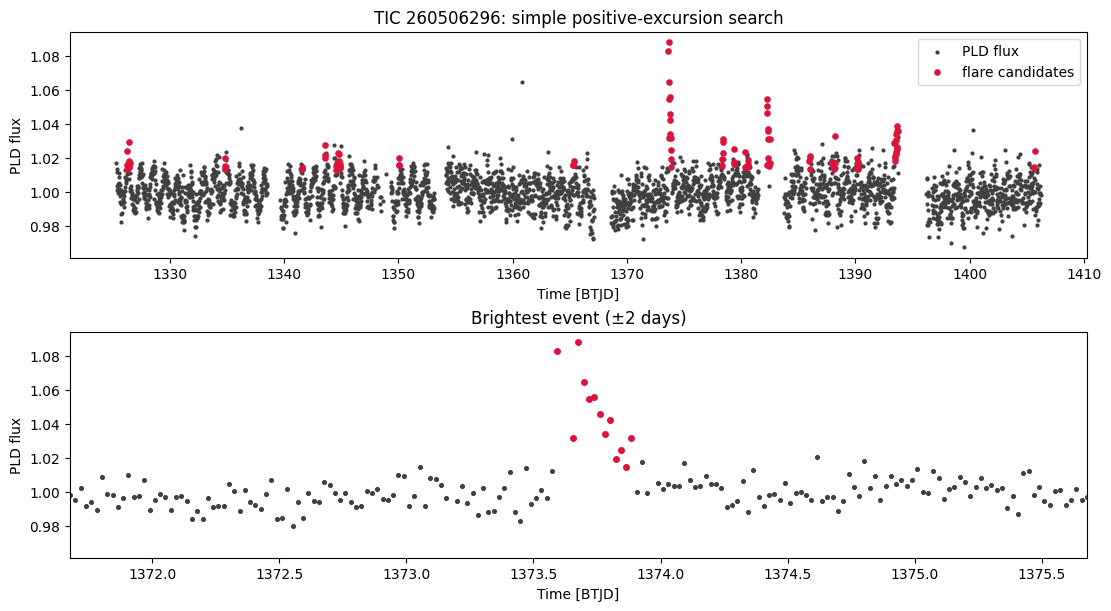

In [3]:
# Two panels as in the showcase: entire baseline and a ±2-day zoom.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), layout='constrained')
ax1.scatter(time, flux, s=4, c='0.25', label='PLD flux')
ax1.scatter(time[mask], flux[mask], s=14, c='crimson', label='flare candidates')
ax1.set(xlabel='Time [BTJD]', ylabel='PLD flux',
        title=f'TIC {TIC_ID}: simple positive-excursion search')
ax1.legend(loc='upper right')
ax2.scatter(time, flux, s=7, c='0.25')
ax2.scatter(time[mask], flux[mask], s=16, c='crimson')
finite = np.flatnonzero(np.isfinite(flux))
if finite.size:
    center = time[finite[np.argmax(flux[finite])]]
    ax2.set_xlim(center - 2.0, center + 2.0)
ax2.set(xlabel='Time [BTJD]', ylabel='PLD flux', title='Brightest event (±2 days)')
plt.show()

**Limitations:** This is the simple method from the showcase, not a vetted
flare catalog. A global median/MAD can misidentify rotational modulation,
short-timescale systematics and data-gap artifacts. Outlier removal and PLD
can also affect flares, so inspect images and test injection/recovery before
publishing occurrence rates or flare energies. The source PDF's plotting
NameError has been corrected (`ax1.set_xlabel`, rather than `ax`).